In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

print("Tout fonctionne !")

Tout fonctionne !


In [6]:
# Charger le jeu de données
housing = fetch_california_housing(as_frame=True)

# Récupérer les données dans un DataFrame
df = housing.frame

# Afficher les premières lignes
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [10]:
# Dimensions du jeu de données
print("Dimensions :", df.shape)

# Informations sur les variables
df.info()

# Statistiques descriptives
df.describe()

Dimensions : (20640, 9)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [11]:
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

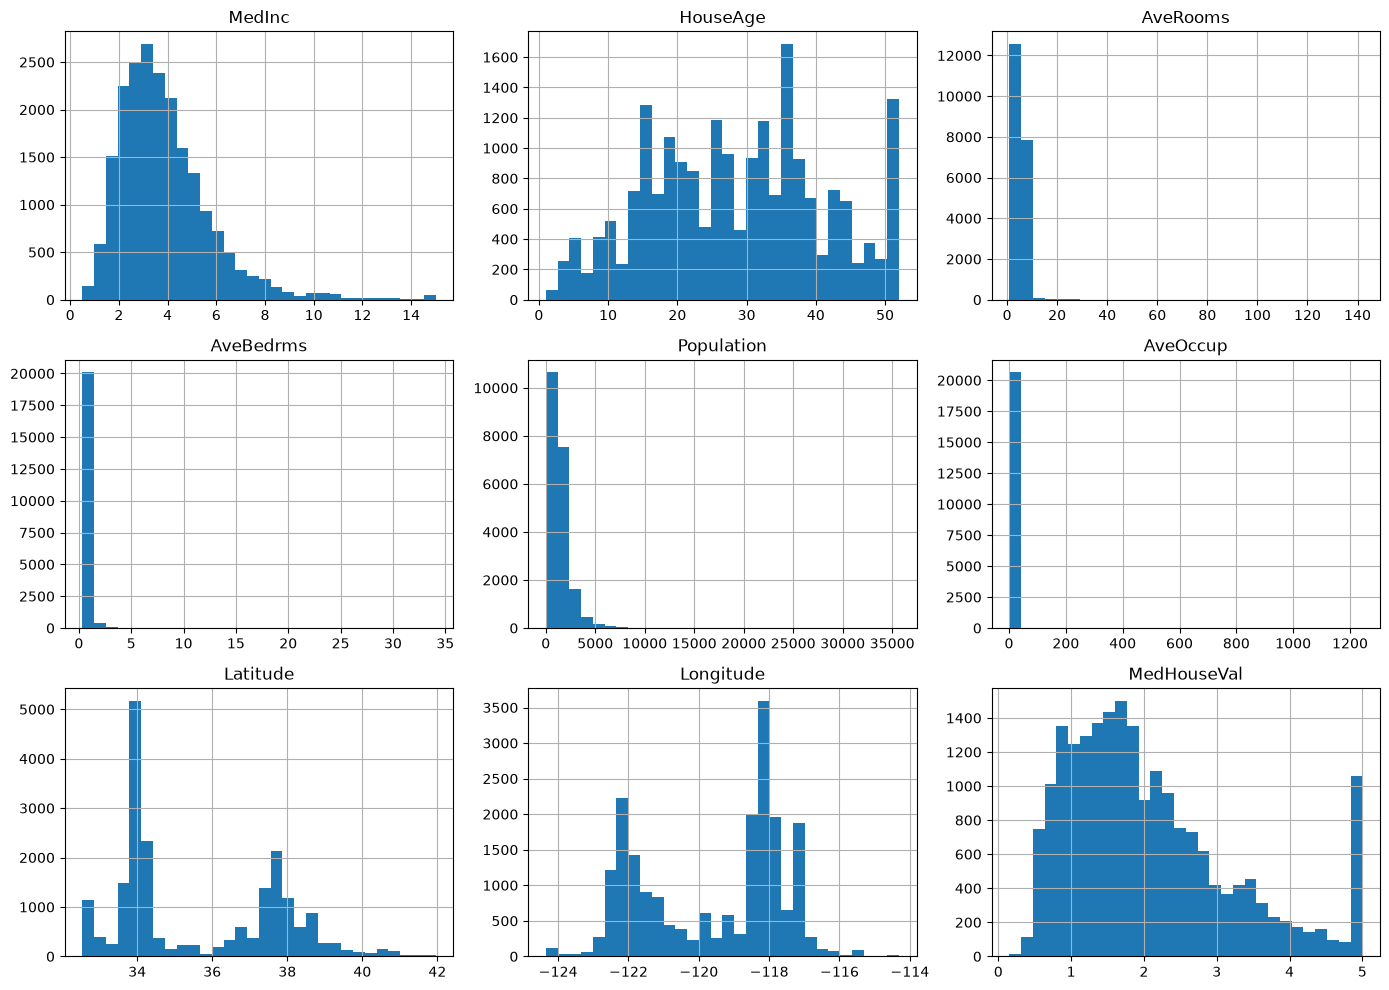

In [12]:
df.hist(figsize=(14, 10), bins=30)

plt.tight_layout()
plt.show()

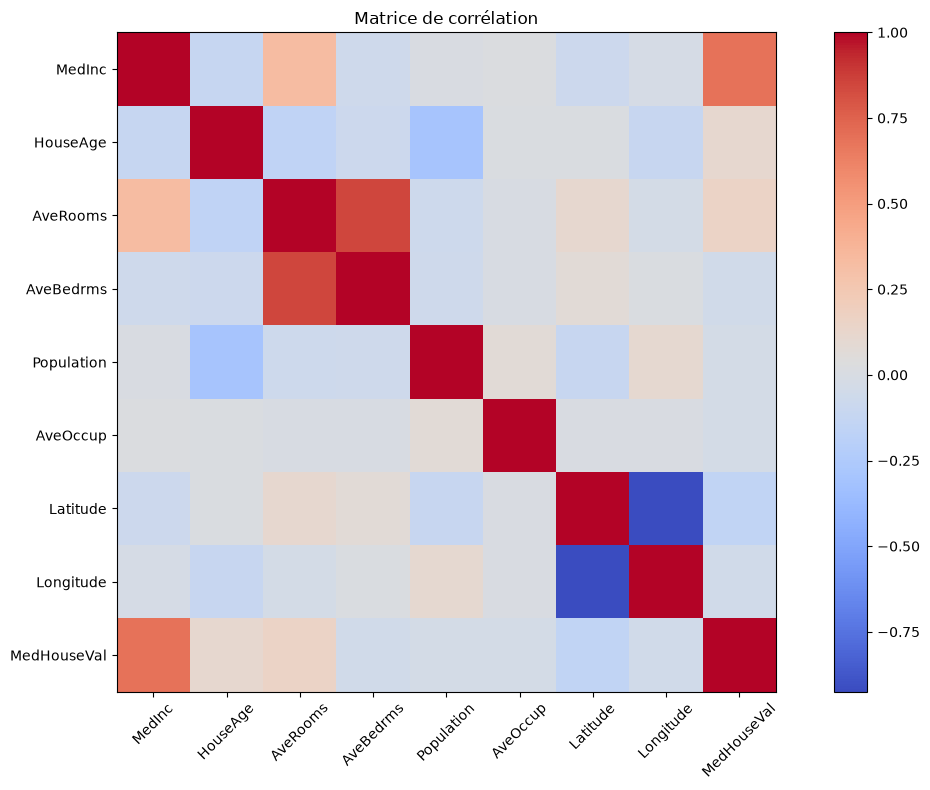

In [13]:
correlation = df.corr()

plt.figure(figsize=(12, 8))

plt.imshow(correlation, cmap="coolwarm")
plt.colorbar()

plt.xticks(range(len(correlation.columns)),
           correlation.columns, rotation=45)

plt.yticks(range(len(correlation.columns)),
           correlation.columns)

plt.title("Matrice de corrélation")

plt.tight_layout()
plt.show()

In [16]:
# Variables explicatives
X = df.drop("MedHouseVal", axis=1)

# Variable cible
y = df["MedHouseVal"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (20640, 8)
Dimensions de y : (20640,)


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Données d'entraînement :", X_train.shape)
print("Données de test :", X_test.shape)

Données d'entraînement : (16512, 8)
Données de test : (4128, 8)


In [18]:
from sklearn.linear_model import LinearRegression

# Création du modèle
model = LinearRegression()

# Entraînement
model.fit(X_train, y_train)

print("Modèle entraîné avec succès !")

Modèle entraîné avec succès !


In [20]:
predictions = model.predict(X_test)

print("Prix réels :", list(y_test[:5]))
print("Prix prédits :", predictions[:5])

Prix réels : [0.477, 0.458, 5.00001, 2.186, 2.78]
Prix prédits : [0.71912284 1.76401657 2.70965883 2.83892593 2.60465725]


In [21]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, predictions)

rmse = mean_squared_error(
    y_test, predictions
) ** 0.5

r2 = r2_score(y_test, predictions)

print("MAE :", mae)
print("RMSE :", rmse)
print("R² :", r2)

MAE : 0.5332001304956556
RMSE : 0.7455813830127763
R² : 0.575787706032451


In [23]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

In [24]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = mean_squared_error(y_test, rf_predictions) ** 0.5
rf_r2 = r2_score(y_test, rf_predictions)

print("MAE :", rf_mae)
print("RMSE :", rf_rmse)
print("R² :", rf_r2)

MAE : 0.32773108008720936
RMSE : 0.5059859946022769
R² : 0.8046244867176197


In [25]:
from sklearn.metrics import r2_score

train_predictions = rf_model.predict(X_train)
test_predictions = rf_model.predict(X_test)

print("R² entraînement :", r2_score(y_train, train_predictions))
print("R² test :", r2_score(y_test, test_predictions))

R² entraînement : 0.9735148362732539
R² test : 0.8046244867176197


In [26]:
rf_model_2 = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model_2.fit(X_train, y_train)

train_pred_2 = rf_model_2.predict(X_train)
test_pred_2 = rf_model_2.predict(X_test)

print("R² entraînement :", r2_score(y_train, train_pred_2))
print("R² test :", r2_score(y_test, test_pred_2))

R² entraînement : 0.8883026694628713
R² test : 0.7898786009080714


In [27]:
from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

print("Entraînement :", X_train_sub.shape)
print("Validation :", X_val.shape)
print("Test final :", X_test.shape)

Entraînement : (13209, 8)
Validation : (3303, 8)
Test final : (4128, 8)


In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Entraînement
model_lr = LinearRegression()
model_lr.fit(X_train_sub, y_train_sub)

# Prédictions sur la validation
pred_lr = model_lr.predict(X_val)

# Évaluation
print("MAE :", mean_absolute_error(y_val, pred_lr))
print("RMSE :", mean_squared_error(y_val, pred_lr) ** 0.5)
print("R² :", r2_score(y_val, pred_lr))

MAE : 0.5407140746076824
RMSE : 0.7338977899061437
R² : 0.6097023914123505


In [29]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Entraînement
rf_model.fit(X_train_sub, y_train_sub)

# Prédictions
pred_rf = rf_model.predict(X_val)

# Évaluation
print("MAE :", mean_absolute_error(y_val, pred_rf))
print("RMSE :", mean_squared_error(y_val, pred_rf) ** 0.5)
print("R² :", r2_score(y_val, pred_rf))

MAE : 0.34475156560702414
RMSE : 0.5272623738490979
R² : 0.7985448882061409


In [30]:
rf_model_2 = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Entraînement
rf_model_2.fit(X_train_sub, y_train_sub)

# Prédictions
pred_rf_2 = rf_model_2.predict(X_val)

# Évaluation
print("MAE :", mean_absolute_error(y_val, pred_rf_2))
print("RMSE :", mean_squared_error(y_val, pred_rf_2) ** 0.5)
print("R² :", r2_score(y_val, pred_rf_2))

MAE : 0.35796905228358855
RMSE : 0.5390440599669204
R² : 0.7894412663770239


In [31]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print("Scores :", scores)
print("R² moyen :", scores.mean())
print("Écart-type :", scores.std())

Scores : [0.80892648 0.79412943 0.80857647 0.80497096 0.8054235 ]
R² moyen : 0.8044053691692102
Écart-type : 0.005381263688186624


In [40]:
from sklearn.model_selection import GridSearchCV

print("GridSearchCV importé avec succès !")
print(GridSearchCV)

GridSearchCV importé avec succès !
<class 'sklearn.model_selection._search.GridSearchCV'>


In [41]:
rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, 15, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_mo

In [43]:
print("Meilleurs paramètres :", grid_search.best_params_)
print("Meilleur R² moyen :", grid_search.best_score_)

Meilleurs paramètres : {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Meilleur R² moyen : 0.8053119034465338


In [44]:
best_model = grid_search.best_estimator_

In [47]:
best_predictions = best_model.predict(X_val)

In [46]:
results = pd.DataFrame({
    "Valeur_reelle": y_val,
    "Prediction": best_predictions
})

results["Erreur"] = results["Valeur_reelle"] - results["Prediction"]
results["Erreur_absolue"] = results["Erreur"].abs()

results.head(10)

,Valeur_reelle,Prediction,Erreur,Erreur_absolue
2071,0.96700,0.986899,-0.019899,0.019899
2612,0.75500,0.863959,-0.108959,0.108959
10838,4.30900,3.241893,1.067107,1.067107
4061,3.32600,3.038353,0.287647,0.287647
10767,5.00001,4.609953,0.390057,0.390057
9778,1.37900,1.542805,-0.163805,0.163805
11317,1.79600,1.781816,0.014184,0.014184
2454,0.95700,0.895786,0.061214,0.061214
10394,1.70800,1.901184,-0.193184,0.193184
20002,0.42500,0.443340,-0.018340,0.018340


In [48]:
print("Statistiques des erreurs signées :")
print(results["Erreur"].describe())

print("\nStatistiques des erreurs absolues :")
print(results["Erreur_absolue"].describe())

Statistiques des erreurs signées :
count    3303.000000
mean       -0.004146
std         0.244536
min        -1.525413
25%        -0.105105
50%        -0.022509
75%         0.061875
max         2.140777
Name: Erreur, dtype: float64

Statistiques des erreurs absolues :
count    3.303000e+03
mean     1.497822e-01
std      1.933224e-01
min      1.776357e-14
25%      3.610487e-02
50%      8.828259e-02
75%      1.867503e-01
max      2.140777e+00
Name: Erreur_absolue, dtype: float64


In [49]:
results["Tranche_prix"] = pd.cut(
    results["Valeur_reelle"],
    bins=[0, 1, 2, 3, 4, 5.01],
    labels=["<100k", "100-200k", "200-300k", "300-400k", "400-500k"]
)

results.groupby("Tranche_prix", observed=False)["Erreur_absolue"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
Tranche_prix,,,
<100k,568,0.094769,0.051801
100-200k,1332,0.112297,0.071336
200-300k,765,0.149558,0.107723
300-400k,332,0.220166,0.163564
400-500k,306,0.339264,0.210099


In [50]:
results.groupby("Tranche_prix", observed=False).agg(
    Erreur_moyenne=("Erreur", "mean"),
    Erreur_absolue_moyenne=("Erreur_absolue", "mean"),
    Nombre=("Erreur", "count")
)

,Erreur_moyenne,Erreur_absolue_moyenne,Nombre
Tranche_prix,,,
<100k,-0.086318,0.094769,568
100-200k,-0.066713,0.112297,1332
200-300k,-0.012971,0.149558,765
300-400k,0.106115,0.220166,332
400-500k,0.323162,0.339264,306


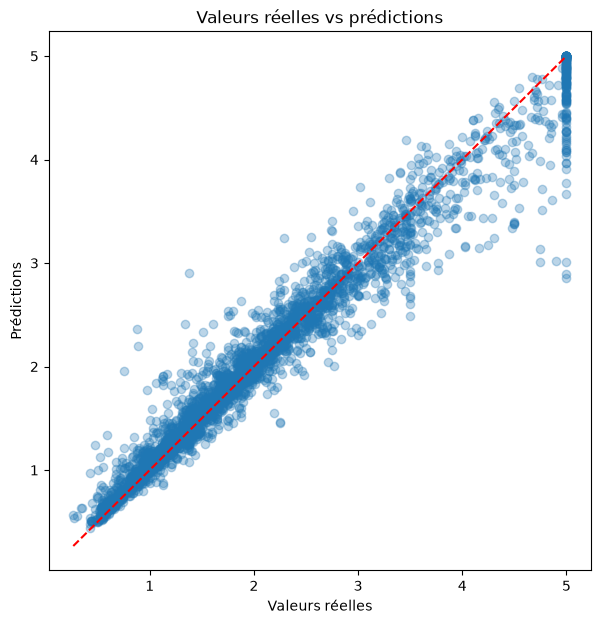

In [51]:
plt.figure(figsize=(7, 7))

plt.scatter(y_val, best_predictions, alpha=0.3)

plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    "r--"
)

plt.xlabel("Valeurs réelles")
plt.ylabel("Prédictions")
plt.title("Valeurs réelles vs prédictions")

plt.show()

MedInc        0.535601
AveOccup      0.138016
Latitude      0.088331
Longitude     0.087854
HouseAge      0.053322
AveRooms      0.042271
Population    0.028029
AveBedrms     0.026577
dtype: float64


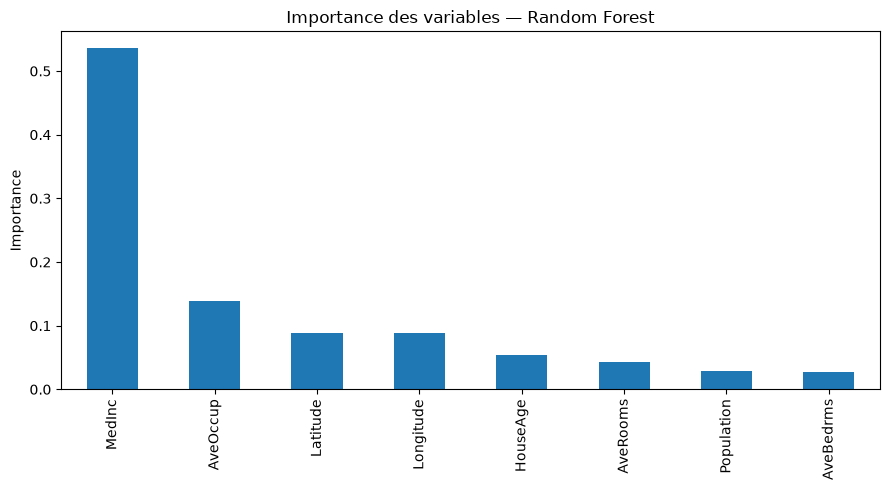

In [52]:
importances = pd.Series(
    best_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importances)

importances.plot(kind="bar", figsize=(9, 5))
plt.title("Importance des variables — Random Forest")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

In [54]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    best_model,
    X_val,
    y_val,
    n_repeats=10,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

perm_results = pd.Series(
    perm_importance.importances_mean,
    index=X_val.columns
).sort_values(ascending=False)

print(perm_results)

MedInc        0.901875
Latitude      0.442091
Longitude     0.351603
AveOccup      0.291935
HouseAge      0.109878
AveRooms      0.067502
AveBedrms     0.034373
Population    0.031531
dtype: float64


In [55]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

grid_search_clean = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

grid_search_clean.fit(X_train_sub, y_train_sub)

print("Meilleurs paramètres :", grid_search_clean.best_params_)
print("Meilleur R² moyen :", grid_search_clean.best_score_)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Meilleurs paramètres : {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Meilleur R² moyen : 0.801208209362645


In [56]:
best_model_clean = grid_search_clean.best_estimator_

val_predictions = best_model_clean.predict(X_val)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE :", mean_absolute_error(y_val, val_predictions))
print("RMSE :", mean_squared_error(y_val, val_predictions)**0.5)
print("R² :", r2_score(y_val, val_predictions))

MAE : 0.3429052981279875
RMSE : 0.5249953219706623
R² : 0.8002735430991325


In [57]:
X_train_sub_no_geo = X_train_sub.drop(
    columns=["Latitude", "Longitude"]
)

X_val_no_geo = X_val.drop(
    columns=["Latitude", "Longitude"]
)

In [58]:
rf_no_geo = RandomForestRegressor(
    **grid_search_clean.best_params_,
    random_state=42,
    n_jobs=-1
)

rf_no_geo.fit(X_train_sub_no_geo, y_train_sub)

predictions_no_geo = rf_no_geo.predict(X_val_no_geo)

print("R² sans géographie :", r2_score(y_val, predictions_no_geo))

R² sans géographie : 0.6892909736360483


In [59]:
X_train_sub_no_income = X_train_sub.drop(columns=["MedInc"])
X_val_no_income = X_val.drop(columns=["MedInc"])

rf_no_income = RandomForestRegressor(
    **grid_search_clean.best_params_,
    random_state=42,
    n_jobs=-1
)

rf_no_income.fit(X_train_sub_no_income, y_train_sub)

predictions_no_income = rf_no_income.predict(X_val_no_income)

print("R² sans MedInc :", r2_score(y_val, predictions_no_income))

R² sans MedInc : 0.8121068378945675


In [60]:
from sklearn.model_selection import cross_val_score

rf_full = RandomForestRegressor(
    **grid_search_clean.best_params_,
    random_state=42,
    n_jobs=-1
)

rf_no_income_cv = RandomForestRegressor(
    **grid_search_clean.best_params_,
    random_state=42,
    n_jobs=-1
)

scores_full = cross_val_score(
    rf_full, X_train_sub, y_train_sub,
    cv=5, scoring="r2", n_jobs=-1
)

scores_no_income = cross_val_score(
    rf_no_income_cv, X_train_sub_no_income, y_train_sub,
    cv=5, scoring="r2", n_jobs=-1
)

print("Avec MedInc :", scores_full)
print("Moyenne :", scores_full.mean())

print("\nSans MedInc :", scores_no_income)
print("Moyenne :", scores_no_income.mean())

Avec MedInc : [0.81610336 0.80221228 0.791445   0.80269289 0.79358751]
Moyenne : 0.801208209362645

Sans MedInc : [0.81611242 0.79527942 0.82538501 0.80746606 0.79776354]
Moyenne : 0.808401291479605


In [61]:
print("Écart-type avec MedInc :", scores_full.std())
print("Écart-type sans MedInc :", scores_no_income.std())

Écart-type avec MedInc : 0.008700265937803407
Écart-type sans MedInc : 0.011261687612930074


In [62]:
from sklearn.inspection import permutation_importance

perm_clean = permutation_importance(
    best_model_clean,
    X_val,
    y_val,
    n_repeats=20,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

perm_results_clean = pd.DataFrame({
    "Importance_moyenne": perm_clean.importances_mean,
    "Ecart_type": perm_clean.importances_std
}, index=X_val.columns).sort_values(
    by="Importance_moyenne",
    ascending=False
)

print(perm_results_clean)

            Importance_moyenne  Ecart_type
MedInc                0.812131    0.018159
Latitude              0.361435    0.008087
Longitude             0.277610    0.007105
AveOccup              0.192646    0.008359
HouseAge              0.062380    0.005430
AveRooms              0.020697    0.001578
Population            0.007262    0.000993
AveBedrms             0.007161    0.001001


In [63]:
correlations = df.corr(numeric_only=True)["MedInc"].drop("MedInc")

correlations = correlations.sort_values(
    key=abs,
    ascending=False
)

print(correlations)

MedHouseVal    0.688075
AveRooms       0.326895
HouseAge      -0.119034
Latitude      -0.079809
AveBedrms     -0.062040
AveOccup       0.018766
Longitude     -0.015176
Population     0.004834
Name: MedInc, dtype: float64


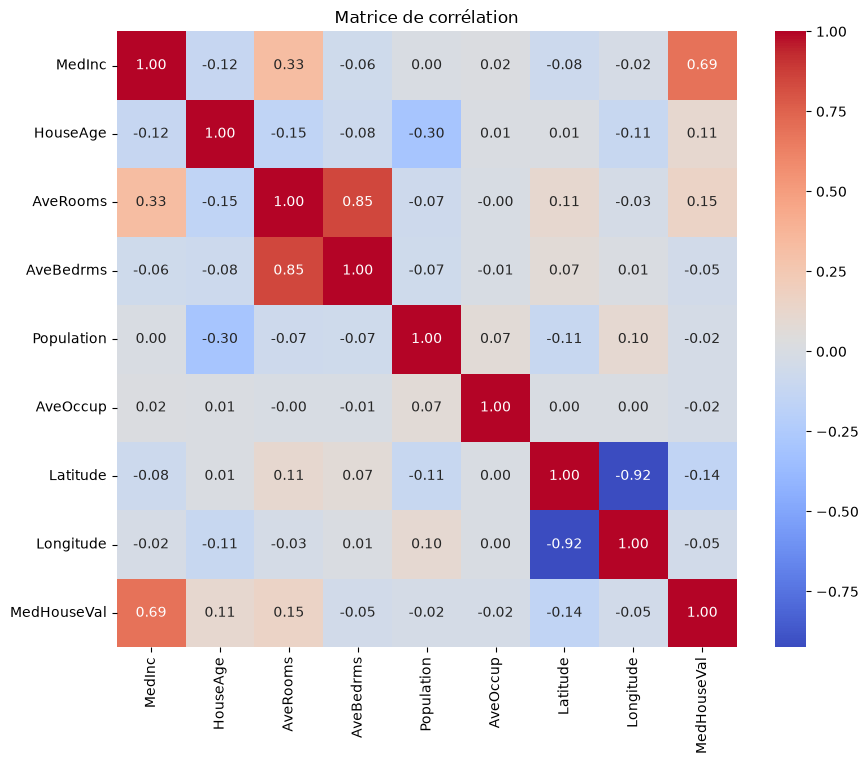

In [64]:
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matrice de corrélation")
plt.show()

In [65]:
results_clean = pd.DataFrame({
    "Valeur_reelle": y_val,
    "Prediction": val_predictions
})

results_clean["Erreur"] = (
    results_clean["Valeur_reelle"] - results_clean["Prediction"]
)

results_clean["Erreur_absolue"] = (
    results_clean["Erreur"].abs()
)

print(results_clean.head(10))

       Valeur_reelle  Prediction    Erreur  Erreur_absolue
2071         0.96700    0.952411  0.014589        0.014589
2612         0.75500    0.925041 -0.170041        0.170041
10838        4.30900    2.128740  2.180260        2.180260
4061         3.32600    2.740175  0.585825        0.585825
10767        5.00001    4.091791  0.908219        0.908219
9778         1.37900    1.559656 -0.180656        0.180656
11317        1.79600    1.823624 -0.027624        0.027624
2454         0.95700    0.790561  0.166439        0.166439
10394        1.70800    2.239316 -0.531316        0.531316
20002        0.42500    0.516395 -0.091395        0.091395


In [66]:
worst_errors = results_clean.sort_values(
    by="Erreur_absolue",
    ascending=False
)

print(worst_errors.head(10))

       Valeur_reelle  Prediction    Erreur  Erreur_absolue
89           5.00001    1.213580  3.786430        3.786430
1914         5.00001    1.443575  3.556435        3.556435
489          4.89600    1.544230  3.351770        3.351770
16556        4.75000    1.438656  3.311344        3.311344
15705        0.87500    4.178125 -3.303125        3.303125
20443        5.00001    1.739505  3.260505        3.260505
1633         4.75000    1.823123  2.926877        2.926877
61           0.75000    3.454975 -2.704975        2.704975
19006        1.37500    4.003675 -2.628675        2.628675
6452         4.76700    2.359731  2.407269        2.407269


In [67]:
results_clean["Categorie_prix"] = pd.cut(
    results_clean["Valeur_reelle"],
    bins=[0, 1, 2, 3, 4, 5.1],
    labels=["0-1", "1-2", "2-3", "3-4", "4-5"]
)

error_by_category = results_clean.groupby(
    "Categorie_prix",
    observed=False
)["Erreur_absolue"].mean()

print(error_by_category)


Categorie_prix
0-1    0.228770
1-2    0.259632
2-3    0.351770
3-4    0.508403
4-5    0.715528
Name: Erreur_absolue, dtype: float64


In [68]:
print(
    results_clean["Categorie_prix"]
    .value_counts()
    .sort_index()
)

Categorie_prix
0-1     568
1-2    1332
2-3     765
3-4     332
4-5     306
Name: count, dtype: int64


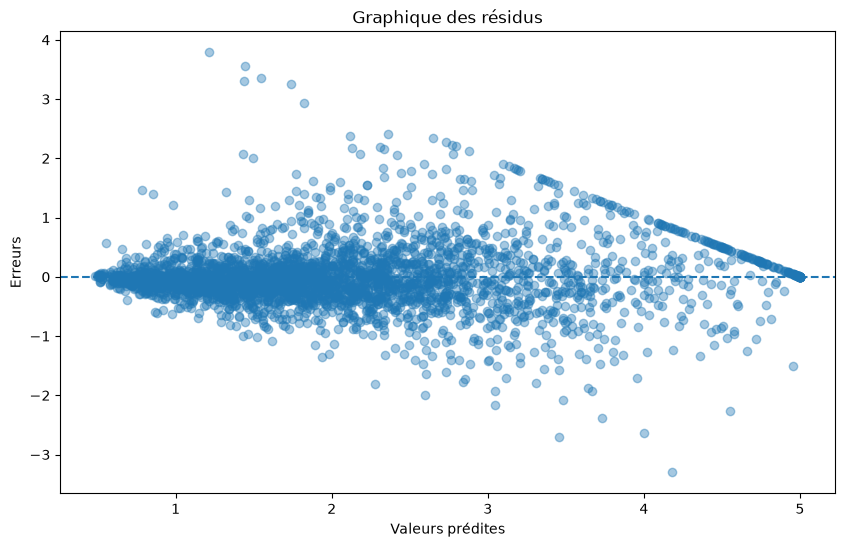

In [69]:
plt.figure(figsize=(10, 6))

plt.scatter(
    results_clean["Prediction"],
    results_clean["Erreur"],
    alpha=0.4
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Valeurs prédites")
plt.ylabel("Erreurs")
plt.title("Graphique des résidus")
plt.show()

In [70]:
final_model = RandomForestRegressor(
    **grid_search_clean.best_params_,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [71]:
test_predictions = final_model.predict(X_test)

In [72]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

test_mae = mean_absolute_error(y_test, test_predictions)

test_rmse = mean_squared_error(y_test, test_predictions) ** 0.5

test_r2 = r2_score(y_test, test_predictions)

print("MAE :", test_mae)
print("RMSE :", test_rmse)
print("R² :", test_r2)

MAE : 0.3260536937316253
RMSE : 0.5039658427733038
R² : 0.8061814480062914
